# Health Insurance Cross-Sell Classification Model

This notebook trains and tests a supervised binary classification model using the MySQL/MariaDB table `customers` loaded by the ETL notebook. The target is `Response`, where `0` means the customer is not interested in vehicle insurance and `1` means they are.

Six models spanning the standard supervised-learning families are compared — **Linear Regression**, **Logistic Regression**, a **Decision Tree**, **K-Nearest Neighbors**, **Random Forest**, and **Hist Gradient Boosting** — the best one is tuned, evaluated on a held-out validation split, then retrained and used to score `data/test.csv` and export the pipeline for the Streamlit app.

Scored by **ROC-AUC** (this Kaggle competition's metric), so the final submission carries predicted probabilities, not hard labels. The model is for educational analysis only and must not be the sole basis for business decisions.


## Instructions

1. Run `health_insurance_etl.ipynb` first so the `customers` table exists in `health_insurance_db` (XAMPP MySQL must be running).
2. Use the project's `.venv` kernel. Dependencies: `pip install -r app/requirements.txt`.
3. Run the cells from top to bottom. The baseline comparison and tuning cells take several minutes on this machine (single-threaded on purpose, see the note in section 4).
4. Evaluate the model using the **validation-set** metrics, confusion matrices, ROC-AUC and the chosen threshold. Never evaluate on the training split.
5. Run the final **Export** cell so the app has both `app/health_insurance_model.joblib` and `app/model_metadata.json`.

The notebook reads from MySQL and does not load `train.csv` directly. `test.csv` is read as a CSV because it is Kaggle's unlabeled holdout and was never loaded into the database.


## Import libraries

In [1]:
# Environment check: makes sure this kernel has every package the notebook needs before anything else runs.
# If it fails, either pick the kernel "Health Insurance (.venv)" (top-right kernel picker) or install the
# missing packages into the selected Python:  python -m pip install -r ../app/requirements.txt
import importlib.util
import sys

required = {'pandas': 'pandas', 'numpy': 'numpy', 'sqlalchemy': 'SQLAlchemy', 'pymysql': 'PyMySQL',
            'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'scipy': 'scipy', 'joblib': 'joblib'}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise ModuleNotFoundError(
        f'This kernel ({sys.executable}) is missing: {", ".join(missing)}. '
        'Fix: select the kernel "Health Insurance (.venv)" in the kernel picker (top-right), '
        f'or run:  "{sys.executable}" -m pip install {" ".join(missing)}'
    )
print(f'Environment OK: {sys.executable}')

Environment OK: D:\Practice\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    make_scorer, roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    precision_recall_curve, confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay,
)

RANDOM_STATE = 42

## 1. Load and prepare data

Loads the `customers` table from the local MySQL/MariaDB database (populated by `health_insurance_etl.ipynb`, browsable in DBeaver) instead of the CSV. Drops `id` (identifier only, not a feature).

In [3]:
from sqlalchemy import create_engine

DB_HOST = 'localhost'
DB_PORT = 3306
DB_USER = 'root'
DB_PASSWORD = ''  # XAMPP default: empty password
DB_NAME = 'health_insurance_db'

engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

COLUMN_RENAME_MAP = {
    'gender': 'Gender', 'age': 'Age', 'driving_license': 'Driving_License',
    'region_code': 'Region_Code', 'previously_insured': 'Previously_Insured',
    'vehicle_age': 'Vehicle_Age', 'vehicle_damage': 'Vehicle_Damage',
    'annual_premium': 'Annual_Premium', 'policy_sales_channel': 'Policy_Sales_Channel',
    'vintage': 'Vintage', 'response': 'Response',
}

# This machine has ~1.5 GB of free RAM. pd.read_sql() without a chunksize calls
# cursor.fetchall(), which materialises all 381,109 rows as Python tuples before the
# DataFrame is built -- that peak is what raised MemoryError here on an earlier run.
# stream_results=True switches PyMySQL to an unbuffered (server-side) cursor and
# chunksize converts the rows in batches, so peak memory stays a few tens of MB.
def load_customers(engine, chunksize=50_000):
    """Read the whole customers table into a DataFrame without a large memory spike."""
    with engine.connect().execution_options(stream_results=True, max_row_buffer=chunksize) as conn:
        chunks = list(pd.read_sql('SELECT * FROM customers', con=conn, chunksize=chunksize))
    return pd.concat(chunks, ignore_index=True)


df = load_customers(engine).rename(columns=COLUMN_RENAME_MAP).drop(columns=['id'])

X = df.drop(columns=['Response'])
y = df['Response']

print(f'X shape: {X.shape}, y shape: {y.shape}')
print(f'Positive rate: {y.mean():.4f}')

X shape: (381109, 10), y shape: (381109,)
Positive rate: 0.1226


## 2. Train / validation split

Stratified so both splits keep the same ~12.3% positive rate.

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape}, Val: {X_val.shape}')
print(f'Train positive rate: {y_train.mean():.4f}, Val positive rate: {y_val.mean():.4f}')

Train: (304887, 10), Val: (76222, 10)
Train positive rate: 0.1226, Val positive rate: 0.1226


## 3. Preprocessing

Two different `ColumnTransformer`s are needed because the model families compared below don't treat features the same way:

- **Tree-based models** (Decision Tree, Random Forest, Hist Gradient Boosting) split on one feature at a time and don't care about scale, so `Region_Code` / `Policy_Sales_Channel` stay as raw passthrough integers. Tree splits can still separate the important codes (the EDA shows the big channels cluster: 152/160 convert poorly, 26/124 well). Hist Gradient Boosting's native categorical handling was also tried for these two codes and scored the same as raw codes (3-fold ROC-AUC 0.8542 vs 0.8540 on a 150k-row sample), so the simpler version is kept.
- **Coefficient- and distance-based models** (Linear Regression, Logistic Regression, K-Nearest Neighbors) are not so forgiving. `Region_Code=52` isn't "more" of anything than `Region_Code=3`. It's a nominal label, yet a linear model would fit one slope across the code numbers, and KNN would treat the numeric gap between two unrelated regions as a real distance. One-hot encoding would avoid that but adds ~200 sparse columns, which hurts KNN in particular.

For those three models the two codes are **target-encoded** with sklearn's `TargetEncoder`: each code is replaced by the response rate of customers with that code (shrunk toward the overall rate when a code has few customers), then scaled. That is exactly the signal the EDA found in these columns: channel 152 converts at 2.9%, channel 26 at 19.9%. To avoid leaking the target, `TargetEncoder.fit_transform` uses internal 5-fold cross-fitting: each training row is encoded with rates computed *without* that row's fold. It is fit inside every CV fold, so validation rows never influence their own encoding.

**Why target encoding rather than frequency encoding:** frequency encoding (replacing each code with how common it is) was the obvious alternative and was measured first. It doesn't work here, because the two most common channels behave oppositely: channel 152 is 35% of customers with a 2.9% response rate, and channel 26 is 21% with 19.9%. On real data (3-fold ROC-AUC; 100k-row sample for Logistic Regression, 30k for KNN):

| Code representation | Logistic Regression | KNN |
|---|---|---|
| Raw code, scaled | 0.8357 | 0.8207 |
| Frequency encoding | 0.8342 | 0.8204 |
| **Target encoding** | **0.8430** | **0.8265** |

`TargetEncoder` is also built into sklearn, so the exported pipeline loads in the Streamlit app with no custom class to import. (A pipeline that uses a class defined in this notebook cannot be unpickled in another process.)

`preprocessor_tree` is used for the three tree-based candidates. `preprocessor_scaled` (one-hot categoricals, scaled numerics, target-encoded codes) is used for Linear Regression, Logistic Regression and KNN.

In [5]:
categorical_features = ['Gender', 'Vehicle_Age', 'Vehicle_Damage']
numeric_scaled_features = ['Age', 'Annual_Premium', 'Vintage']
high_card_features = ['Region_Code', 'Policy_Sales_Channel']
binary_passthrough_features = ['Driving_License', 'Previously_Insured']

# Used by Decision Tree / Random Forest / Hist Gradient Boosting
preprocessor_tree = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_scaled_features),
    ('pass', 'passthrough', binary_passthrough_features + high_card_features),
])

# Used by Linear Regression / Logistic Regression / K-Nearest Neighbors.
# The cv splitter (not random_state) sets TargetEncoder's cross-fitting shuffle: random_state is
# deprecated for TargetEncoder in scikit-learn 1.9.
target_encoder = TargetEncoder(target_type='binary', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
preprocessor_scaled = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_scaled_features),
    ('codes', Pipeline([('encode', target_encoder), ('scale', StandardScaler())]), high_card_features),
    ('pass', 'passthrough', binary_passthrough_features),
])

## 4. Baseline model comparison

Six candidates, chosen to cover the standard supervised-learning families: a plain linear model (**Linear Regression**), its classification-correct counterpart (**Logistic Regression**), a single **Decision Tree**, a distance-based model (**K-Nearest Neighbors**), and two tree ensembles (**Random Forest**, **Hist Gradient Boosting**).

**Linear Regression is included for comparison, not because it's the right tool.** `Response` is a 0/1 label, and OLS doesn't know that: its output is an unbounded real number, not a probability, and nothing stops it from predicting -0.3 or 1.8. It is scored below on ROC-AUC and PR-AUC, which only depend on the *ranking* of scores and tolerate that. It is **not** scored on F1, since turning an unbounded score into a yes/no call at a fixed cutoff isn't meaningful. Logistic Regression is the linear model actually built for this problem (bounded, probabilistic output) and is scored the same way as the other classifiers.

Because `LinearRegression` has neither `predict_proba` nor `decision_function`, sklearn's `scoring='roc_auc'` shortcut can't score it directly. `make_scorer(..., response_method=(...))` is used instead with an explicit fallback order (`predict_proba` → `decision_function` → `predict`), so one scoring dict works for every candidate.

**KNN is compared on a stratified 40,000-row subsample of the training split, not the full ~305k rows.** KNN has no real training step. The cost is at prediction time, where it measures the distance from every query point to every stored training point. At this row count that is slow (single-threaded, per the memory note below), and KNN is weaker in high dimensions generally (one-hot encoding adds several more columns). The subsample keeps the comparison fast. It is **not** an apples-to-apples row count against the other models, so that gap is recorded in the results table's `notes` column.

**Compare on `roc_auc` and `avg_precision`, not `f1`.** The F1 column uses a fixed 0.5 cutoff, and the candidates don't agree on what 0.5 means. Logistic Regression, the Decision Tree and Random Forest use `class_weight='balanced'`, which pushes their probabilities up. Hist Gradient Boosting and KNN are unweighted, so with only 12% positives they rarely reach 0.5. A low F1 here says more about where each model's probabilities sit than about how well it ranks customers. A proper cutoff is chosen for the winning model in Section 6.

In [6]:
def get_scores(fitted_pipeline, X):
    """Predicted probability of the positive class when available, else the raw
    prediction. Every candidate but Linear Regression has predict_proba; this keeps
    the rest of the notebook from caring which one won."""
    model = fitted_pipeline.named_steps['model']
    if hasattr(model, 'predict_proba'):
        return fitted_pipeline.predict_proba(X)[:, 1]
    if hasattr(model, 'decision_function'):
        return fitted_pipeline.decision_function(X)
    return fitted_pipeline.predict(X)


# Scorers built with an explicit response_method fallback chain, so the same scoring
# dict works whether the model exposes predict_proba (every classifier here) or only
# predict() (Linear Regression).
roc_auc_scorer = make_scorer(roc_auc_score, response_method=('predict_proba', 'decision_function', 'predict'))
avg_precision_scorer = make_scorer(average_precision_score, response_method=('predict_proba', 'decision_function', 'predict'))
scoring_classifiers = {'roc_auc': 'roc_auc', 'avg_precision': 'average_precision', 'f1': 'f1'}
scoring_linear_regression = {'roc_auc': roc_auc_scorer, 'avg_precision': avg_precision_scorer}  # no f1: see markdown above

# KNN's cost is at prediction time and scales with the training-set size, so it is
# compared (and later tuned) on a smaller stratified subsample rather than the full
# ~305k-row training split.
KNN_SAMPLE_SIZE = 40_000
X_train_knn, _, y_train_knn, _ = train_test_split(
    X_train, y_train, train_size=KNN_SAMPLE_SIZE, stratify=y_train, random_state=RANDOM_STATE
)

# Random Forest: leaves of >= 20 rows and a half-size bootstrap sample per tree. Unconstrained
# leaves (min_samples_leaf=1) grew a 134 MB forest per fold that ran this machine out of memory
# mid-CV, and also scored worse on a held-out fold (ROC-AUC 0.850 vs 0.856 for this setting, 19 MB).
candidates = {
    'Linear Regression': (preprocessor_scaled, LinearRegression(), X_train, y_train),
    'Logistic Regression': (preprocessor_scaled, LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE), X_train, y_train),
    'Decision Tree': (preprocessor_tree, DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=RANDOM_STATE), X_train, y_train),
    'K-Nearest Neighbors': (preprocessor_scaled, KNeighborsClassifier(n_neighbors=25, n_jobs=1), X_train_knn, y_train_knn),
    'Random Forest': (preprocessor_tree, RandomForestClassifier(
        class_weight='balanced', n_estimators=100, max_depth=20, min_samples_leaf=20, max_samples=0.5,
        n_jobs=1, random_state=RANDOM_STATE), X_train, y_train),
    'Hist Gradient Boosting': (preprocessor_tree, HistGradientBoostingClassifier(random_state=RANDOM_STATE), X_train, y_train),
}

# n_jobs=1 everywhere in this notebook (not -1): this machine has only ~2.3GB free RAM,
# and nested parallelism (CV folds x model's own multiprocessing) exhausted the page file
# and crashed the kernel on the first attempt. Single-threaded is slower but reliable here.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_summary = []
for name, (preprocessor, model, X_fit, y_fit) in candidates.items():
    pipe = Pipeline([('preprocess', preprocessor), ('model', model)])
    scoring = scoring_linear_regression if name == 'Linear Regression' else scoring_classifiers
    # error_score='raise': a fold that fails (e.g. out of memory) stops here, instead of
    # becoming a silent NaN row that quietly drops that model out of the comparison.
    scores = cross_validate(pipe, X_fit, y_fit, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
    cv_summary.append({
        'model': name,
        'roc_auc': scores['test_roc_auc'].mean(),
        'avg_precision': scores['test_avg_precision'].mean(),
        'f1': scores['test_f1'].mean() if 'test_f1' in scores else np.nan,
        'rows_used': len(X_fit),
        'notes': (
            '40k-row subsample, not the full training split' if name == 'K-Nearest Neighbors'
            else 'no F1: raw OLS output is not a probability' if name == 'Linear Regression'
            else ''
        ),
    })
    print(f'{name}: done')

cv_results = pd.DataFrame(cv_summary).sort_values('roc_auc', ascending=False).reset_index(drop=True)
cv_results

Linear Regression: done


Logistic Regression: done


Decision Tree: done


K-Nearest Neighbors: done


Random Forest: done


Hist Gradient Boosting: done


,model,roc_auc,avg_precision,f1,rows_used,notes
0,Hist Gradient Boosting,0.856580,0.366876,0.007750,304887,
1,Random Forest,0.855122,0.365951,0.429918,304887,
2,Decision Tree,0.846683,0.343313,0.427243,304887,
3,Logistic Regression,0.844075,0.325246,0.419843,304887,
4,Linear Regression,0.841522,0.322974,NaN,304887,no F1: raw OLS output is not a probability
5,K-Nearest Neighbors,0.823661,0.306014,0.064490,40000,"40k-row subsample, not the full training split"


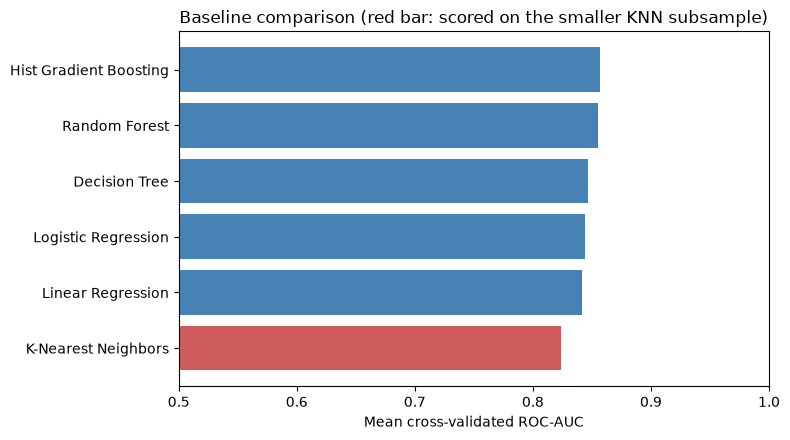

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = cv_results.sort_values('roc_auc')
bar_colors = ['indianred' if n == 'K-Nearest Neighbors' else 'steelblue' for n in plot_data['model']]
ax.barh(plot_data['model'], plot_data['roc_auc'], color=bar_colors)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('Mean cross-validated ROC-AUC')
ax.set_title('Baseline comparison (red bar: scored on the smaller KNN subsample)')
plt.tight_layout()
plt.show()

## 5. Hyperparameter tuning

Tunes the best baseline with `RandomizedSearchCV` (grid search would be too slow at this row count). Decision Tree and KNN are new search spaces here; KNN tuning reuses the same 40,000-row subsample as the baseline comparison, for the same prediction-time-cost reason. Linear Regression has no hyperparameters worth searching (plain OLS) and sklearn's `scoring='roc_auc'` string can't score it anyway (no `predict_proba`/`decision_function`) — if it were ever the best baseline, tuning is skipped and it is used as-is.

In [8]:
best_model_name = cv_results.iloc[0]['model']
print(f'Best baseline: {best_model_name}')

model_preprocessors = {
    'Linear Regression': preprocessor_scaled,
    'Logistic Regression': preprocessor_scaled,
    'Decision Tree': preprocessor_tree,
    'K-Nearest Neighbors': preprocessor_scaled,
    'Random Forest': preprocessor_tree,
    'Hist Gradient Boosting': preprocessor_tree,
}
model_estimators = {
    'Linear Regression': LinearRegression(),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(n_jobs=1),
    'Random Forest': RandomForestClassifier(class_weight='balanced', max_samples=0.5, n_jobs=1, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
param_distributions = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10],
    },
    'Decision Tree': {
        'model__max_depth': [5, 10, 15, 20, None],
        'model__min_samples_leaf': [1, 5, 10, 20],
    },
    'K-Nearest Neighbors': {
        'model__n_neighbors': [11, 25, 51, 75],
        'model__weights': ['uniform', 'distance'],
    },
    'Random Forest': {  # min_samples_leaf >= 10 keeps the forest small enough for this machine (see Section 4)
        'model__n_estimators': [100, 200],
        'model__max_depth': [15, 20, 25],
        'model__min_samples_leaf': [10, 20, 50],
    },
    'Hist Gradient Boosting': {
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_leaf_nodes': [15, 31, 63],
        'model__max_iter': [150, 300],
    },
}

if best_model_name == 'Linear Regression':
    # Plain OLS has no hyperparameters worth searching here, and the 'roc_auc' scoring
    # string RandomizedSearchCV expects can't score it anyway (no predict_proba /
    # decision_function) -- so it is used as-is rather than tuned.
    print('Linear Regression has no hyperparameters to tune; using it as-is.')
    search = None
    tuned_model = Pipeline([
        ('preprocess', model_preprocessors[best_model_name]),
        ('model', model_estimators[best_model_name]),
    ])
    tuned_model.fit(X_train, y_train)
else:
    tuning_X, tuning_y = (X_train_knn, y_train_knn) if best_model_name == 'K-Nearest Neighbors' else (X_train, y_train)
    search_pipe = Pipeline([
        ('preprocess', model_preprocessors[best_model_name]),
        ('model', model_estimators[best_model_name]),
    ])

    search = RandomizedSearchCV(
        search_pipe,
        param_distributions=param_distributions[best_model_name],
        n_iter=4,
        scoring='roc_auc',
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1,
        error_score='raise',
    )
    search.fit(tuning_X, tuning_y)

    print('Best params:', search.best_params_)
    print('Best CV ROC-AUC:', search.best_score_)

    tuned_model = search.best_estimator_

Best baseline: Hist Gradient Boosting
Fitting 3 folds for each of 4 candidates, totalling 12 fits


Best params: {'model__max_leaf_nodes': 31, 'model__max_iter': 150, 'model__learning_rate': 0.03}
Best CV ROC-AUC: 0.8569043762515678


## 6. Final evaluation on the held-out validation set

ROC-AUC and PR-AUC are threshold-independent, and they're what this competition is scored on. But with only ~12% positives, a 0.5 cutoff is a poor operating point for real yes/no cross-sell calls, so an F1-optimal threshold is also chosen.

**The threshold is chosen without looking at the validation set.** It comes from 3-fold *out-of-fold* predictions on the training split: each training row is scored by a copy of the tuned model that never saw it. The F1-maximising cutoff on those predictions is then applied once to the validation set. Picking the cutoff on the validation rows and reporting F1 on the same rows would overstate how well it generalises. The same threshold is exported to the app in Section 11.

`get_scores` (defined in Section 4) is used rather than `predict_proba` directly, since the winner could in principle be Linear Regression, which has no `predict_proba`. In that case the values below are raw unbounded scores rather than probabilities. ROC-AUC/PR-AUC are still valid (they only depend on ranking), but the 0.5 default-threshold comparison loses its usual meaning.

In [9]:
threshold_X, threshold_y = (X_train_knn, y_train_knn) if best_model_name == 'K-Nearest Neighbors' else (X_train, y_train)
oof_method = 'predict_proba' if hasattr(tuned_model.named_steps['model'], 'predict_proba') else 'predict'
oof_scores = cross_val_predict(
    clone(tuned_model), threshold_X, threshold_y,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    method=oof_method, n_jobs=1,
)
if oof_method == 'predict_proba':
    oof_scores = oof_scores[:, 1]

oof_precisions, oof_recalls, oof_thresholds = precision_recall_curve(threshold_y, oof_scores)
oof_f1 = 2 * oof_precisions * oof_recalls / (oof_precisions + oof_recalls + 1e-12)
best_threshold = oof_thresholds[np.argmax(oof_f1[:-1])]  # last precision/recall point has no matching threshold
print(f'F1-optimal threshold, chosen on out-of-fold training predictions: {best_threshold:.3f}')

val_proba = get_scores(tuned_model, X_val)
roc_auc = roc_auc_score(y_val, val_proba)
pr_auc = average_precision_score(y_val, val_proba)
print(f'\nValidation ROC-AUC: {roc_auc:.4f}')
print(f'Validation PR-AUC:  {pr_auc:.4f}')

for label, threshold in [('0.5 (default)', 0.5), (f'{best_threshold:.3f} (F1-optimal, chosen out-of-fold)', best_threshold)]:
    pred = (val_proba >= threshold).astype(int)
    print(f'\n--- Threshold = {label} ---')
    print(f'F1: {f1_score(y_val, pred):.4f}')
    print('Confusion matrix:')
    print(confusion_matrix(y_val, pred))
    print(classification_report(y_val, pred, zero_division=0))

val_pred_best = (val_proba >= best_threshold).astype(int)
val_f1_at_threshold = f1_score(y_val, val_pred_best)
val_precision_at_threshold = precision_score(y_val, val_pred_best, zero_division=0)
val_recall_at_threshold = recall_score(y_val, val_pred_best)

F1-optimal threshold, chosen on out-of-fold training predictions: 0.229



Validation ROC-AUC: 0.8576
Validation PR-AUC:  0.3673

--- Threshold = 0.5 (default) ---
F1: 0.0026
Confusion matrix:
[[66868    12]
 [ 9330    12]]
              precision    recall  f1-score   support

           0       0.88      1.00      0.93     66880
           1       0.50      0.00      0.00      9342

    accuracy                           0.88     76222
   macro avg       0.69      0.50      0.47     76222
weighted avg       0.83      0.88      0.82     76222


--- Threshold = 0.229 (F1-optimal, chosen out-of-fold) ---


F1: 0.4601
Confusion matrix:
[[52686 14194]
 [ 2309  7033]]
              precision    recall  f1-score   support

           0       0.96      0.79      0.86     66880
           1       0.33      0.75      0.46      9342

    accuracy                           0.78     76222
   macro avg       0.64      0.77      0.66     76222
weighted avg       0.88      0.78      0.82     76222



## 7. ROC and Precision-Recall curves

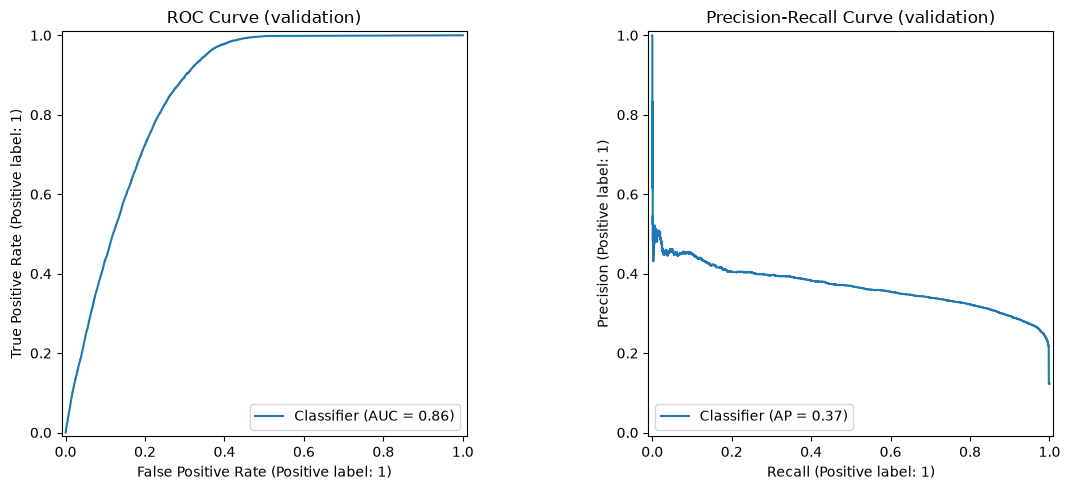

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_val, val_proba, ax=axes[0])
axes[0].set_title('ROC Curve (validation)')
PrecisionRecallDisplay.from_predictions(y_val, val_proba, ax=axes[1])
axes[1].set_title('Precision-Recall Curve (validation)')
plt.tight_layout()
plt.show()

## 8. Inspect feature importance

Permutation importance is used regardless of which model won tuning: each feature's values are shuffled on the validation set and the drop in ROC-AUC is recorded. This works the same way whether the winner is a linear model (coefficients), a tree (`feature_importances_`), or KNN (which has neither) — so the method doesn't have to change if a different model wins on a future run. The `roc_auc_scorer` from Section 4 is reused here so Linear Regression can be scored too. A large drop means the model relies on that feature. These are associations learned from this dataset, not causal effects.

A 20,000-row stratified sample of the validation split keeps this cell fast; the ranking is stable at that size.


,feature,roc_auc_drop_mean,roc_auc_drop_std
0,Previously_Insured,0.1965,0.0041
1,Vehicle_Damage,0.0664,0.0033
2,Age,0.0354,0.0019
3,Policy_Sales_Channel,0.0311,0.0025
4,Vehicle_Age,0.0105,0.0007
5,Region_Code,0.0028,0.0004
6,Annual_Premium,0.0015,0.0001
7,Gender,0.0003,0.0001
8,Driving_License,0.0002,0.0001
9,Vintage,-0.0002,0.0001


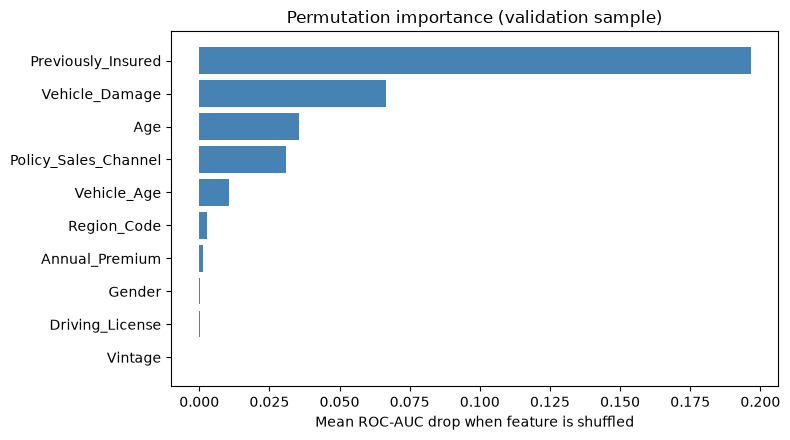

In [11]:
from sklearn.inspection import permutation_importance

X_perm, _, y_perm, _ = train_test_split(
    X_val, y_val, train_size=20_000, stratify=y_val, random_state=RANDOM_STATE
)
perm = permutation_importance(
    tuned_model, X_perm, y_perm, scoring=roc_auc_scorer, n_repeats=5, random_state=RANDOM_STATE, n_jobs=1
)
importance_table = (
    pd.DataFrame({'feature': X_perm.columns, 'roc_auc_drop_mean': perm.importances_mean, 'roc_auc_drop_std': perm.importances_std})
    .sort_values('roc_auc_drop_mean', ascending=False)
    .reset_index(drop=True)
)
display(importance_table.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance_table['feature'][::-1], importance_table['roc_auc_drop_mean'][::-1], color='steelblue')
ax.set_xlabel('Mean ROC-AUC drop when feature is shuffled')
ax.set_title('Permutation importance (validation sample)')
plt.tight_layout()
plt.show()


## 9. Retrain on full data and score the Kaggle test set

Refits the tuned pipeline, then predicts scores on `test.csv` and writes `data/submission.csv` in `sample_submission.csv`'s format.

`test.csv` stays a CSV load here on purpose: it's Kaggle's unlabeled holdout set (no `Response` column) and was never loaded into the `customers` table by the ETL notebook, so there is no database table for it to come from.

Every candidate refits on the full ~381k-row training data **except K-Nearest Neighbors**, which keeps the 40,000-row subsample from Sections 4-5: KNN has no training cost but an expensive prediction cost that scales with the training-set size, and scoring ~127k test rows against the full training set would be far slower than this machine can comfortably do.

In [12]:
from pathlib import Path

# Resolve data/ and app/ from the project root so this works whether the kernel started in
# notebook/ (the Jupyter / VS Code default) or in the project folder itself.
working_directory = Path.cwd()
project_root = working_directory.parent if working_directory.name == 'notebook' else working_directory
submission_path = project_root / 'data' / 'submission.csv'

# K-Nearest Neighbors has no real training step but an expensive prediction step that
# scales with the training-set size too -- refitting it on the full ~381k rows would make
# scoring the ~127k test rows prohibitively slow on this machine. It keeps the same 40k-row
# subsample used during tuning instead; every other model refits on the full training data.
if best_model_name == 'K-Nearest Neighbors':
    refit_X, refit_y = X_train_knn, y_train_knn
    print('K-Nearest Neighbors: refitting on the 40k-row subsample (see note above), not the full data.')
else:
    refit_X, refit_y = X, y

tuned_model.fit(refit_X, refit_y)

test_df = pd.read_csv(project_root / 'data' / 'test.csv')
test_ids = test_df['id']
X_test = test_df.drop(columns=['id'])

test_proba = get_scores(tuned_model, X_test)

submission = pd.DataFrame({'id': test_ids, 'Response': test_proba})
submission.to_csv(submission_path, index=False)
print(f'Wrote {len(submission):,} rows to {submission_path}')
submission.head()

Wrote 127,037 rows to D:\Practice\data\submission.csv


,id,Response
0,381110,0.001807
1,381111,0.295649
2,381112,0.290273
3,381113,0.009165
4,381114,0.001807


## 10. Interpretation and limitations

**What to record:** the validation ROC-AUC and PR-AUC, the confusion matrix at *both* thresholds, and the top permutation-importance features. Expect `Previously_Insured` and `Vehicle_Damage` to dominate, followed by `Age`, `Policy_Sales_Channel` and `Vehicle_Age`, with `Vintage` near zero: the same ranking the statistical-analysis notebook found by effect size.

**Threshold matters more than the model here.** Only ~12.3% of customers respond, so at the default 0.5 cutoff the model predicts almost nobody as interested (F1 near 0) even when its ROC-AUC is good. Compare the two threshold blocks printed in Section 6 for the actual numbers on your run. At the F1-optimal threshold it trades precision for recall instead. Which point is right depends on the cost of a wasted call versus a missed sale, which this data does not contain.

**Limitations, some specific to which model won:**
- One random split can give unstable estimates, and the class imbalance means accuracy is misleading, regardless of the winner.
- If a **tree-based** model won (Decision Tree, Random Forest, Hist Gradient Boosting), `Region_Code` and `Policy_Sales_Channel` are still raw anonymised codes passed through as numbers, so a split like "channel < 140" groups codes that have nothing in common. In practice this costs little here: treating them as true categories in Hist Gradient Boosting gave the same ROC-AUC (Section 3).
- If **K-Nearest Neighbors** won, its score came from a 40,000-row subsample at every stage (comparison, tuning, threshold choice, and the final refit in Section 9). Its behaviour on the full ~381k-row dataset is untested here.
- If **Linear Regression** won (unlikely, since it isn't built for a 0/1 target), its "probabilities" are raw unbounded OLS output, not calibrated frequencies (Section 4).
- There is no external validation and no calibration check for any model, so even a well-behaved classifier's probabilities are rankings, not guaranteed frequencies.

Before real use, add probability calibration, a cost-based operating point instead of F1, a fairness review across `Gender`/`Age`, and monitoring for drift.


## 11. Export the trained model for the app

Run this cell after evaluating the model. It saves the **complete** preprocessing + model pipeline (not just the model), so the app applies the same encoders, scalers and target encodings to user input. It writes the out-of-fold F1-optimal threshold and the validation metrics to `app/model_metadata.json` for the app's decision-threshold slider, then reloads the artifact and checks it reproduces the test-set scores.


In [13]:
import json

artifact_path = project_root / 'app' / 'health_insurance_model.joblib'
metadata_path = project_root / 'app' / 'model_metadata.json'
artifact_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(tuned_model, artifact_path)
print(f'Saved trained pipeline to {artifact_path}')

metadata = {
    'model': f'{best_model_name} (tuned)' if search is not None else best_model_name,
    'best_params': search.best_params_ if search is not None else {},
    'feature_columns': X.columns.tolist(),
    'baseline_cv_roc_auc': {row.model: round(float(row.roc_auc), 4) for row in cv_results.itertuples()},
    'validation_roc_auc': round(float(roc_auc), 4),
    'validation_pr_auc': round(float(pr_auc), 4),
    'f1_optimal_threshold': round(float(best_threshold), 3),
    'threshold_selection': 'F1-optimal on 3-fold out-of-fold predictions of the training split',
    'validation_f1_at_threshold': round(float(val_f1_at_threshold), 4),
    'validation_precision_at_threshold': round(float(val_precision_at_threshold), 4),
    'validation_recall_at_threshold': round(float(val_recall_at_threshold), 4),
}
# allow_nan=False: NaN is not valid JSON, so fail here rather than write a file other tools can't parse.
metadata_path.write_text(json.dumps(metadata, indent=2, allow_nan=False), encoding='utf-8')
print(f'Saved model metadata to {metadata_path}')

# Round-trip check: the saved file must load and reproduce the test-set scores.
reloaded_model = joblib.load(artifact_path)
assert np.allclose(get_scores(reloaded_model, X_test), test_proba), 'Reloaded model predictions differ'
print('Reload check passed.')


Saved trained pipeline to D:\Practice\app\health_insurance_model.joblib
Saved model metadata to D:\Practice\app\model_metadata.json


Reload check passed.
